In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
import os
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Define the device (GPU if available)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Define paths
train_path = r"D:\deeplearning\vscode deep\Birds_25\train"
val_path = r"D:\deeplearning\vscode deep\Birds_25\val"
test_path = r"D:\deeplearning\vscode deep\Birds_25\test"

# Define data transformations
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}


In [2]:
# Load datasets using ImageFolder
train_dataset = datasets.ImageFolder(root=train_path, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(root=val_path, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(root=test_path, transform=data_transforms['test'])

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)

# Load MobileNetV3-Large model pretrained on ImageNet
model = models.mobilenet_v3_large(pretrained=True)

# Modify the final layer to match the number of classes in your dataset
num_ftrs = model.classifier[3].in_features
model.classifier[3] = nn.Linear(num_ftrs, len(train_dataset.classes))

# Move the model to the device (GPU or CPU)
model = model.to(device)


c:\Users\bhore\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\bhore\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Large_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Large_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to C:\Users\bhore/.cache\torch\hub\checkpoints\mobilenet_v3_large-8738ca79.pth
100.0%


In [3]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimizer: SGD with momentum
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)


In [5]:
# Set the number of epochs
num_epochs = 20

for epoch in range(num_epochs):
    print(f'Epoch {epoch+1}/{num_epochs}')
    print('-' * 10)

    # Training phase
    model.train()
    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Zero the gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        # Backward pass + optimization
        loss.backward()
        optimizer.step()

        # Track loss and accuracy
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = running_corrects.double() / len(train_dataset)

    print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

    # Validation phase
    model.eval()
    val_loss = 0.0
    val_corrects = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            val_corrects += torch.sum(preds == labels.data)

    val_loss = val_loss / len(val_dataset)
    val_acc = val_corrects.double() / len(val_dataset)

    print(f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')

print('Training complete')


Epoch 1/20
----------
Train Loss: 0.9060 Acc: 0.7889
Val Loss: 0.2056 Acc: 0.9483
Epoch 2/20
----------
Train Loss: 0.2049 Acc: 0.9432
Val Loss: 0.0982 Acc: 0.9768
Epoch 3/20
----------
Train Loss: 0.1268 Acc: 0.9640
Val Loss: 0.0582 Acc: 0.9881
Epoch 4/20
----------
Train Loss: 0.0902 Acc: 0.9746
Val Loss: 0.0386 Acc: 0.9914
Epoch 5/20
----------
Train Loss: 0.0649 Acc: 0.9830
Val Loss: 0.0282 Acc: 0.9937
Epoch 6/20
----------
Train Loss: 0.0500 Acc: 0.9877
Val Loss: 0.0182 Acc: 0.9967
Epoch 7/20
----------
Train Loss: 0.0385 Acc: 0.9906
Val Loss: 0.0133 Acc: 0.9980
Epoch 8/20
----------
Train Loss: 0.0307 Acc: 0.9926
Val Loss: 0.0104 Acc: 0.9981
Epoch 9/20
----------
Train Loss: 0.0262 Acc: 0.9937
Val Loss: 0.0077 Acc: 0.9986
Epoch 10/20
----------
Train Loss: 0.0219 Acc: 0.9947
Val Loss: 0.0065 Acc: 0.9988
Epoch 11/20
----------
Train Loss: 0.0202 Acc: 0.9953
Val Loss: 0.0051 Acc: 0.9995
Epoch 12/20
----------
Train Loss: 0.0165 Acc: 0.9963
Val Loss: 0.0042 Acc: 0.9994
Epoch 13/20
-

In [ ]:
# Save the trained model's state dictionary
model_save_path = 'mobilenetv3_large_bird_classification.pth'
torch.save(model.state_dict(), model_save_path)

print(f"Model saved to {model_save_path}")


Test Loss: 0.0476 Acc: 0.9872


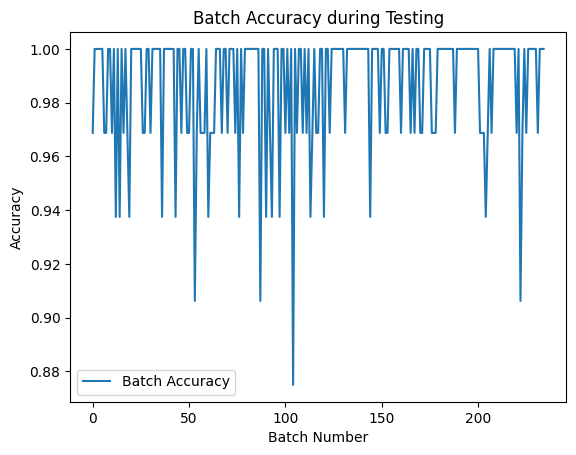

In [7]:
# Testing phase
model.eval()
test_loss = 0.0
test_corrects = 0
accuracy_list = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * inputs.size(0)
        test_corrects += torch.sum(preds == labels.data)
        
        # Calculate accuracy for each batch
        batch_acc = torch.sum(preds == labels.data).double() / inputs.size(0)
        accuracy_list.append(batch_acc.item())

test_loss = test_loss / len(test_dataset)
test_acc = test_corrects.double() / len(test_dataset)

print(f'Test Loss: {test_loss:.4f} Acc: {test_acc:.4f}')

# Plot accuracy for each batch
plt.plot(accuracy_list, label='Batch Accuracy')
plt.xlabel('Batch Number')
plt.ylabel('Accuracy')
plt.title('Batch Accuracy during Testing')
plt.legend()
plt.show()


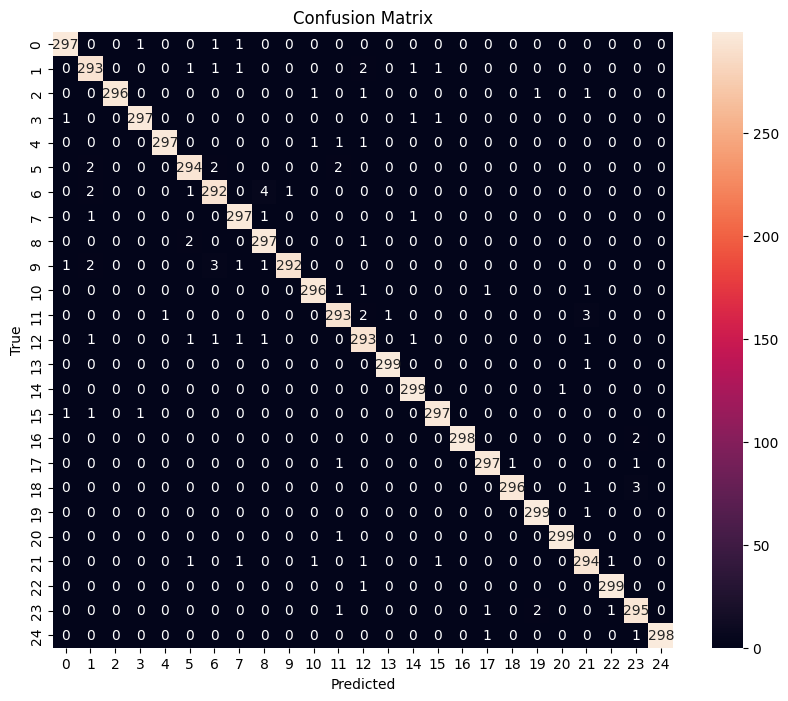

In [8]:
# Compute and plot confusion matrix
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


In [9]:
from sklearn.metrics import classification_report

# Collect all predictions and true labels
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate classification report
report = classification_report(all_labels, all_preds, target_names=test_dataset.classes)
print(report)


                           precision    recall  f1-score   support

    Asian-Green-Bee-Eater       0.99      0.99      0.99       300
      Brown-Headed-Barbet       0.97      0.98      0.97       300
             Cattle-Egret       1.00      0.99      0.99       300
        Common-Kingfisher       0.99      0.99      0.99       300
              Common-Myna       1.00      0.99      0.99       300
         Common-Rosefinch       0.98      0.98      0.98       300
        Common-Tailorbird       0.97      0.97      0.97       300
       Coppersmith-Barbet       0.98      0.99      0.99       300
           Forest-Wagtail       0.98      0.99      0.98       300
             Gray-Wagtail       1.00      0.97      0.98       300
                   Hoopoe       0.99      0.99      0.99       300
               House-Crow       0.98      0.98      0.98       300
     Indian-Grey-Hornbill       0.97      0.98      0.97       300
           Indian-Peacock       1.00      1.00      1.00     